In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("/content/diabetes_prediction_dataset.csv")

/tmp/ipython-input-2950112034.py:1: DtypeWarning: Columns (2,3,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/diabetes_prediction_dataset.csv")


In [ ]:
print("\n----- HEAD -----")
display(df.head(10))

print("\n----- INFO -----")
display(df.info())


----- HEAD -----


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,blood_low,sugar_lvl,payment
0,females,0.0,no,yes,never,25 19,6.6,140.0,0.0,0,Normal,VISA/Mastercard
1,woman,54.0,no,0,No Info,27.32,6.6,80.0,0.0,0,Normal,VISA/Mastercard
2,Male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Normal,VISA/Mastercard
3,fe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,Normal,VISA/Mastercard
4,males,NaN,yes,1,current,20 14,4.8,155.0,0.0,0,Normal,VISA/Mastercard
5,fe,20.0,0,0,never,27.32,6.6,85.0,0.0,0,Normal,VISA/Mastercard
6,Female,40.0,0,no,never,19 31,6.5,200.0,1.0,0,Normal,VISA/Mastercard
7,f,79.0,0,0,No Info,23 86,5.7,85.0,0.0,0,Normal,VISA/Mastercard
8,Male,42.0,no,0,never,33.64,4.8,0.0,0.0,0,Normal,VISA/Mastercard
9,girl,32.0,0,no,never,27.32,5.0,NaN,0.0,0,Normal,VISA/Mastercard



----- INFO -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               99868 non-null   object 
 1   age                  99849 non-null   float64
 2   hypertension         99521 non-null   object 
 3   heart_disease        99521 non-null   object 
 4   smoking_history      99521 non-null   object 
 5   bmi                  99521 non-null   object 
 6   HbA1c_level          99538 non-null   float64
 7   blood_glucose_level  99527 non-null   float64
 8   diabetes             99557 non-null   float64
 9   blood_low            100000 non-null  int64  
 10  sugar_lvl            100000 non-null  object 
 11  payment              100000 non-null  object 
dtypes: float64(4), int64(1), object(7)
memory usage: 9.2+ MB


None

In [ ]:
print("\n----- UNIQUE VALUES PER COLUMN -----")
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique()[:15])


----- UNIQUE VALUES PER COLUMN -----

gender:
['females' 'woman' 'Male' 'fe' 'males' 'Female' 'f' 'girl' 'women' 'girls'
 'm' nan 'boy' 'man' 'men']

age:
[ 0. 54. nan 20. 40. 79. 42. 32. 67. 15. 37.  5. 69. 72.  4.]

hypertension:
['no' nan 'yes' '0' '1' 0 1]

heart_disease:
['yes' '0' nan '1' 'no' 0 1]

smoking_history:
['never' 'No Info' nan 'current' 'former' 'ever' 'not current']

bmi:
['25 19' '27.32' nan '20 14' '19 31' '23 86' '33.64' '27 32' '54.7'
 '36.05' '25.69' '30.36' '24 48' '36.38' '18.8']

HbA1c_level:
[6.6 nan 4.8 6.5 5.7 5.  6.1 6.  5.8 3.5 6.2 4.  4.5 9.  7. ]

blood_glucose_level:
[140.  80.  nan 155.  85. 200.   0. 126. 158.  90. 145. 260. 160. 159.
 100.]

diabetes:
[ 0. nan  1.]

blood_low:
[0]

sugar_lvl:
['Normal']

payment:
['VISA/Mastercard']


In [ ]:
print("\n----- DESCRIPTION -----")
display(df.describe())


----- DESCRIPTION -----


,age,HbA1c_level,blood_glucose_level,diabetes,blood_low
count,99849.000000,99538.000000,99527.000000,99557.000000,100000.0
mean,41.885181,5.527614,138.050750,0.085087,0.0
std,22.516740,1.070895,40.737119,0.279012,0.0
min,0.000000,3.500000,0.000000,0.000000,0.0
25%,24.000000,4.800000,100.000000,0.000000,0.0
50%,43.000000,5.800000,140.000000,0.000000,0.0
75%,60.000000,6.200000,159.000000,0.000000,0.0
max,80.000000,9.000000,300.000000,1.000000,0.0


In [ ]:
print("\n----- MISSING VALUES -----")
print(df.isnull().sum())


----- MISSING VALUES -----
gender                 132
age                    151
hypertension           479
heart_disease          479
smoking_history        479
bmi                    479
HbA1c_level            462
blood_glucose_level    473
diabetes               443
blood_low                0
sugar_lvl                0
payment                  0
dtype: int64


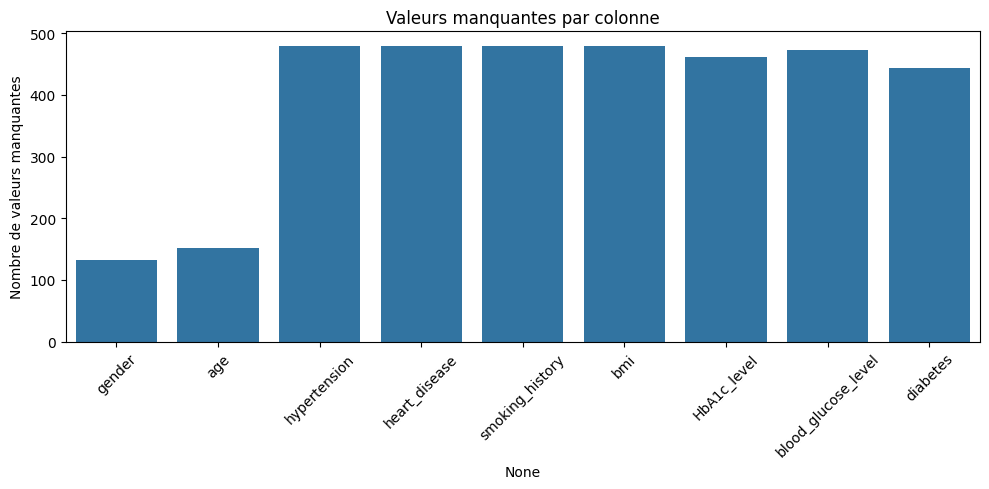

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count missing values per column
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]  # keep only columns with missing values

plt.figure(figsize=(10,5))
sns.barplot(x=missing_counts.index, y=missing_counts.values)
plt.xticks(rotation=45)
plt.ylabel("Nombre de valeurs manquantes")
plt.title("Valeurs manquantes par colonne")
plt.tight_layout()
plt.savefig("missing_values_barplot.png", dpi=300)
plt.show()


In [ ]:
print("\n----- DUPLICATES -----")
print(df.duplicated().sum())


----- DUPLICATES -----
2611



----- TARGET DISTRIBUTION -----


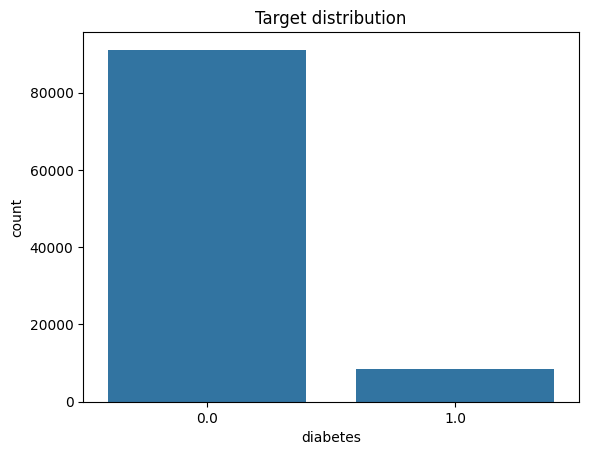

In [ ]:
print("\n----- TARGET DISTRIBUTION -----")
sns.countplot(data=df, x="diabetes")
plt.title("Target distribution")
plt.show()

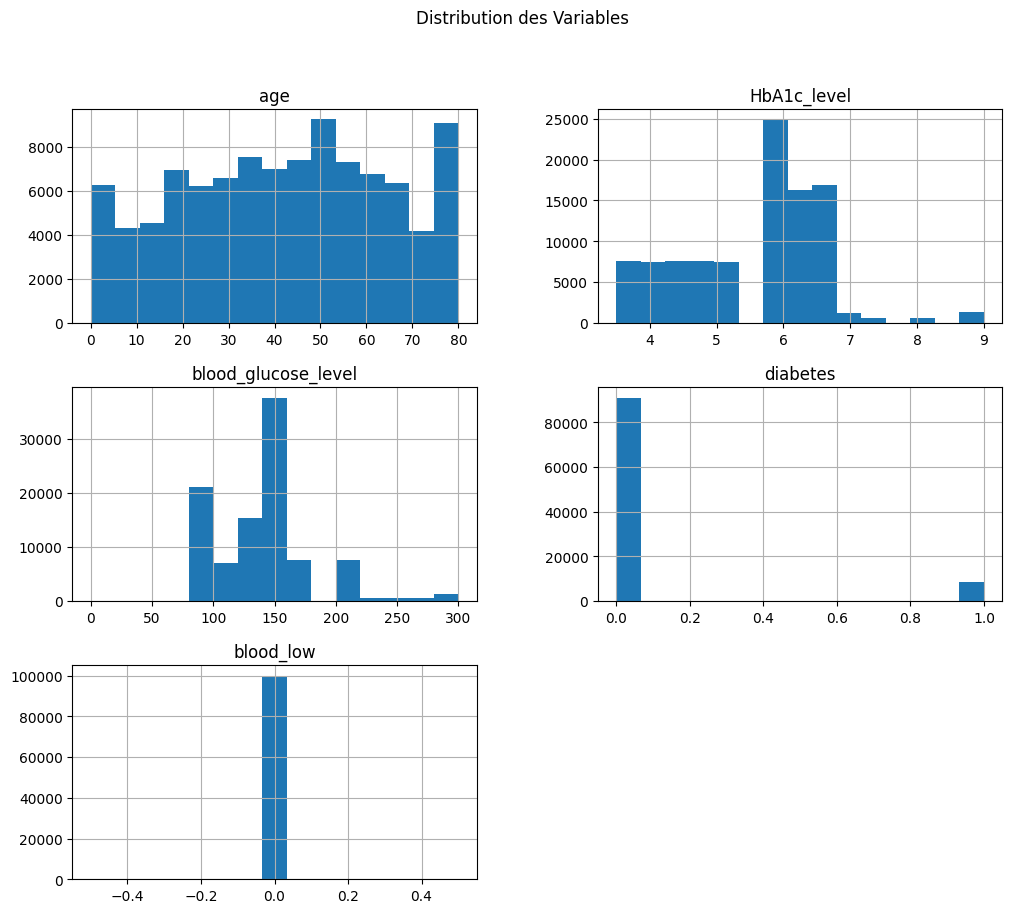

In [ ]:
df.hist(figsize=(12, 10), bins=15)
plt.suptitle("Distribution des Variables")
plt.show()

In [ ]:
# STEP 2 : CLEAN GENDER COLUMN

df['gender'] = df['gender'].astype(str).str.lower().str.strip()

# Define female groups
female_terms = ['female', 'females', 'woman', 'women', 'fe', 'f']

# Define male groups
male_terms = ['male', 'males', 'man', 'men', 'ma', 'm']

In [ ]:
# Map values
def clean_gender(g):
    if g in female_terms:
        return "female"
    elif g in male_terms:
        return "male"
    else:
        return "other"

df['gender'] = df['gender'].apply(clean_gender)

print(df['gender'].value_counts())

gender
female    58448
male      41358
other       194
Name: count, dtype: int64


In [ ]:
import re


def clean_bmi(value):
    value = str(value).strip()

    if value.lower() in ["nan", "", "none"]:
        return None

    if re.match(r"^\d+\s+\d+$", value):
        # convert "25 19" → "25.19"
        parts = value.split()
        return float(parts[0] + "." + parts[1])
    try:
        return float(value)
    except:
        return None

df["bmi"] = df["bmi"].apply(clean_bmi)

# Remove physiologically impossible BMI (<10 or >80)
df.loc[(df["bmi"] < 10) | (df["bmi"] > 80), "bmi"] = None

print(df["bmi"].head(20))
print("Missing BMI:", df["bmi"].isnull().sum())

0     25.19
1     27.32
2       NaN
3       NaN
4     20.14
5     27.32
6     19.31
7     23.86
8     33.64
9     27.32
10    27.32
11    54.70
12    36.05
13    25.69
14      NaN
15    27.32
16    30.36
17    24.48
18    27.32
19    27.32
Name: bmi, dtype: float64
Missing BMI: 488


In [ ]:

def clean_binary(value):
    value = str(value).strip().lower()

    if value in ["yes", "1", "true"]:
        return 1
    elif value in ["no", "0", "false"]:
        return 0
    else:
        return None

df["hypertension"] = df["hypertension"].apply(clean_binary)
df["heart_disease"] = df["heart_disease"].apply(clean_binary)

print(df["hypertension"].value_counts(dropna=False))
print(df["heart_disease"].value_counts(dropna=False))


hypertension
0.0    92076
1.0     7445
NaN      479
Name: count, dtype: int64
heart_disease
0.0    95602
1.0     3919
NaN      479
Name: count, dtype: int64


In [ ]:

df["smoking_history"] = df["smoking_history"].astype(str).str.lower().str.strip()

mapping = {
    "never": "never",
    "no info": "unknown",
    "none": "unknown",
    "nan": "unknown",
    "current": "current",
    "former": "former",
    "ever": "never",
    "not current": "former"
}

df["smoking_history"] = df["smoking_history"].apply(lambda x: mapping[x] if x in mapping else "unknown")

print(df["smoking_history"].value_counts())


smoking_history
never      38895
unknown    36131
former     15731
current     9243
Name: count, dtype: int64


In [ ]:

df["sugar_lvl"] = df["sugar_lvl"].astype(str).str.lower().str.strip()

sugar_map = {
    "low": "low",
    "normal": "normal",
    "high": "high",
    "nan": None,
    "none": None
}

df["sugar_lvl"] = df["sugar_lvl"].apply(lambda x: sugar_map[x] if x in sugar_map else None)

print(df["sugar_lvl"].value_counts(dropna=False))


sugar_lvl
normal    100000
Name: count, dtype: int64


In [ ]:
print("Nombre de doublons avant :", df.duplicated().sum())

df = df.drop_duplicates()

print("Nombre de doublons après :", df.duplicated().sum())

print("Nouvelle taille du dataset :", df.shape)


Nombre de doublons avant : 4370
Nombre de doublons après : 0
Nouvelle taille du dataset : (95630, 12)


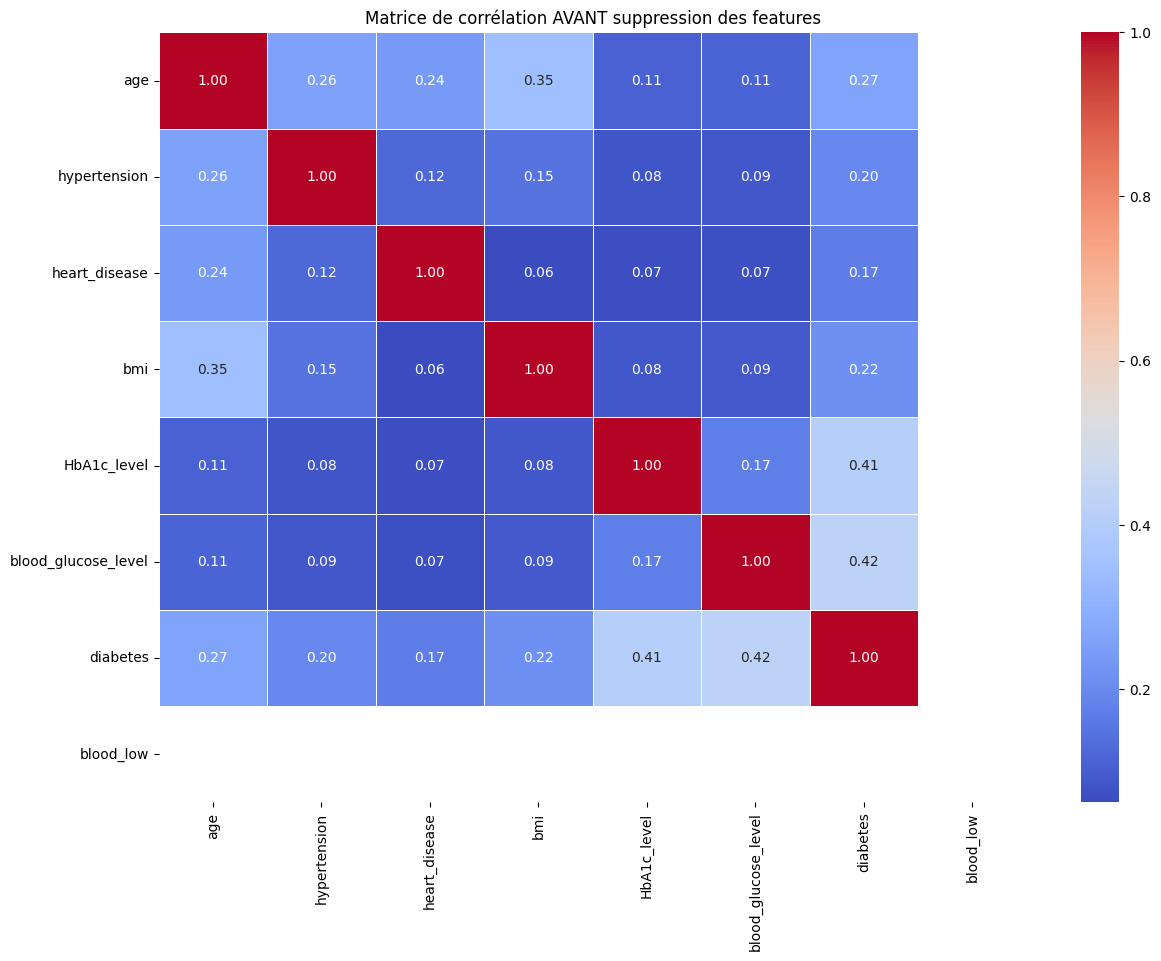

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Copie du dataframe original
df_before_drop = df.copy()

# Sélection uniquement des colonnes numériques
df_corr = df_before_drop.select_dtypes(include=["int64", "float64"])

# Calcul de la matrice de corrélation
corr_matrix = df_corr.corr()

# Affichage
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Matrice de corrélation ")
plt.show()


In [ ]:

cols_to_drop = []

if "payment" in df.columns:
    cols_to_drop.append("payment")

if df["blood_low"].nunique() == 1:
    cols_to_drop.append("blood_low")

df = df.drop(columns=cols_to_drop, errors="ignore")

print("Colonnes supprimées :", cols_to_drop)
print("Shape finale du dataset :", df.shape)
print("Colonnes restantes :", df.columns.tolist())


Colonnes supprimées : ['payment', 'blood_low']
Shape finale du dataset : (95630, 10)
Colonnes restantes : ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'sugar_lvl']


In [ ]:
print("Missing target before:", df["diabetes"].isnull().sum())

df = df.dropna(subset=["diabetes"])

print("Missing target after:", df["diabetes"].isnull().sum())
print("New dataset shape:", df.shape)


Missing target before: 143
Missing target after: 0
New dataset shape: (95487, 10)


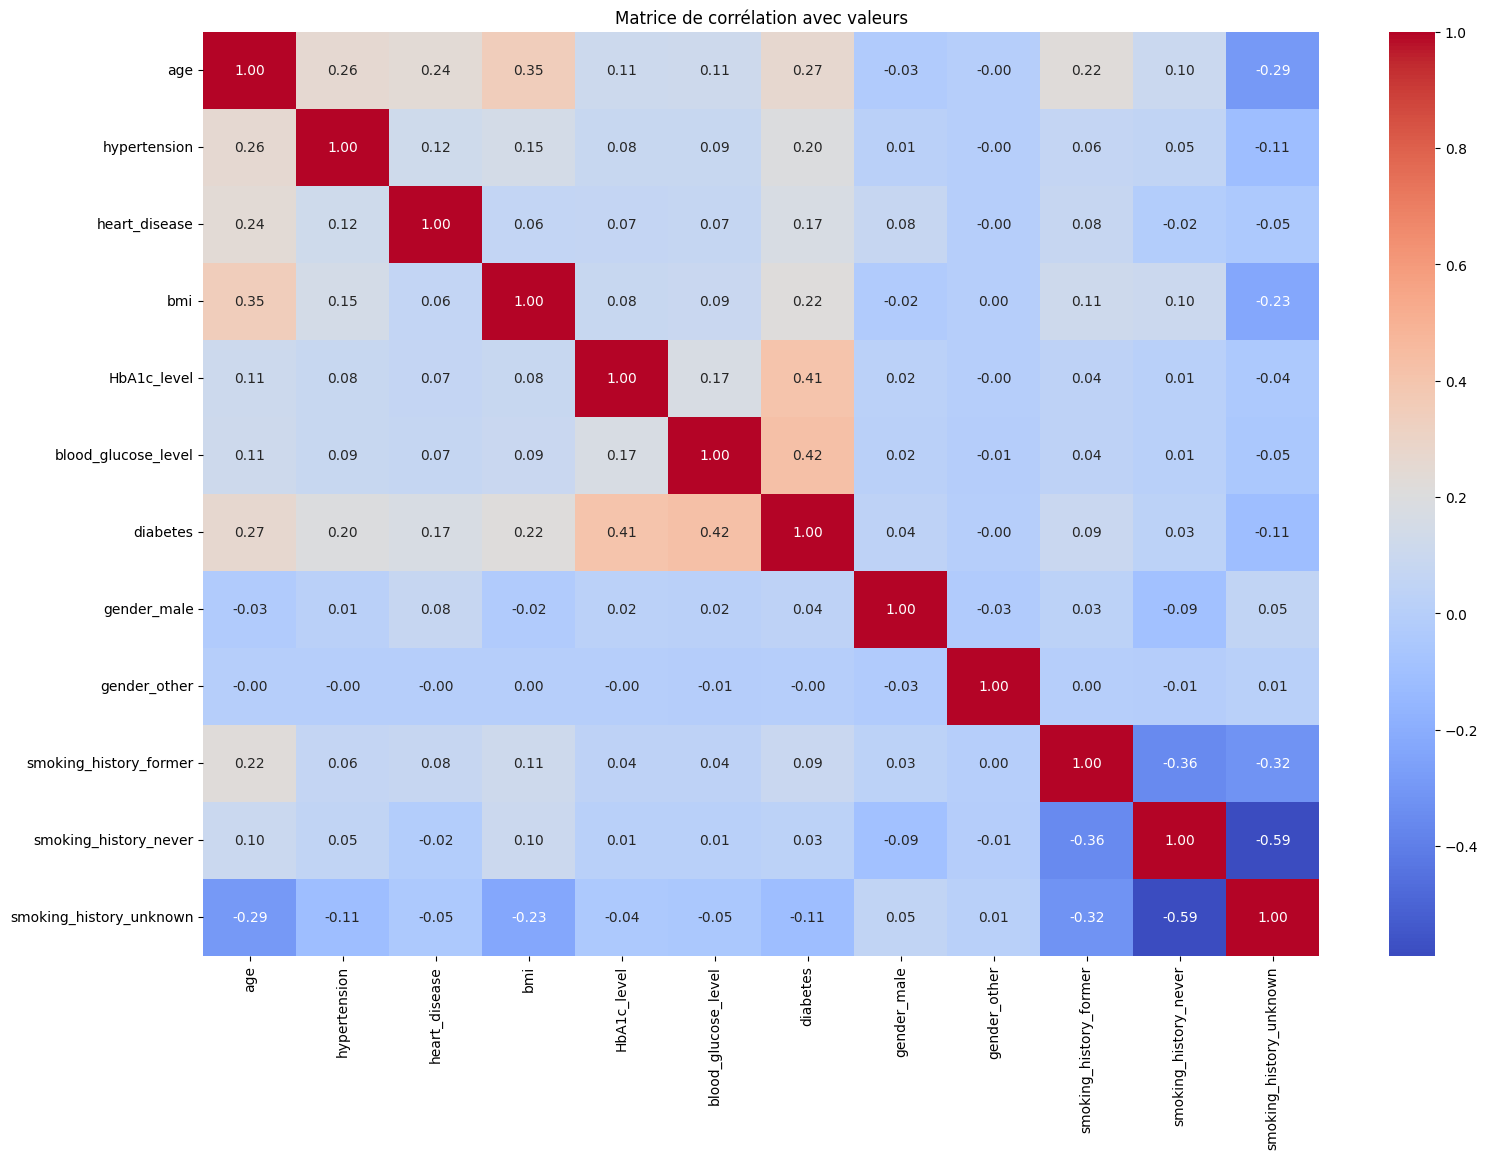

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df_corr = df.copy()

df_corr = pd.get_dummies(df_corr, drop_first=True)

corr_matrix = df_corr.corr()

plt.figure(figsize=(18, 12))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation avec valeurs")
plt.show()



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import numpy as np



df["diabetes"] = df["diabetes"].astype(int)


X = df.drop("diabetes", axis=1)
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
binary_cols = ["hypertension", "heart_disease"]
cat_cols = ["gender", "smoking_history"]
ordinal_cols = ["sugar_lvl"]

# Ordinal order
sugar_order = [["low", "normal", "high"]]

# Pipeline


preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),
        ("binary", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent"))
        ]), binary_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols),

        ("ordinal", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(categories=sugar_order))
        ]), ordinal_cols),
    ],
    remainder="drop"
)


preprocessor.fit(X_train)

X_train_prepared = preprocessor.transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Train shape after preprocessing:", X_train_prepared.shape)
print("Test shape after preprocessing:", X_test_prepared.shape)


Train shape after preprocessing: (76389, 14)
Test shape after preprocessing: (19098, 14)


In [ ]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = sm.fit_resample(X_train_prepared, y_train)

print("Before balancing:", y_train.value_counts())
print("After balancing:", y_train_balanced.value_counts())


Before balancing: diabetes
0    69630
1     6759
Name: count, dtype: int64
After balancing: diabetes
0    69630
1    69630
Name: count, dtype: int64


Before SMOTE:
 diabetes
0    69630
1     6759
Name: count, dtype: int64

After SMOTE:
 diabetes
0    69630
1    69630
Name: count, dtype: int64


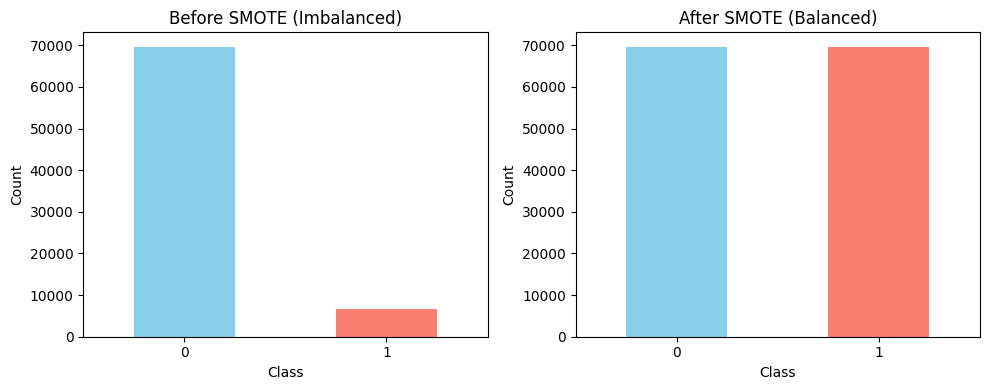

In [ ]:
import matplotlib.pyplot as plt

print("Before SMOTE:\n", y_train.value_counts())
print("\nAfter SMOTE:\n", y_train_balanced.value_counts())

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
y_train.value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title("Before SMOTE (Imbalanced)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.subplot(1,2,2)
y_train_balanced.value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title("After SMOTE (Balanced)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


In [ ]:
# PUT THE FUNCTION HERE
from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred)

    y_test_pred = model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_f1 = f1_score(y_test, y_test_pred)

    print("\n🔷 MODEL REPORT")
    print("Training Accuracy :", train_accuracy)
    print("Training F1       :", train_f1)
    print("Testing Accuracy  :", test_accuracy)
    print("Testing F1        :", test_f1)

    return train_accuracy, train_f1, test_accuracy, test_f1

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report


In [ ]:
try:
  from xgboost import XGBClassifier
  xgb_available = True
except:
   xgb_available = False
models = { "Logistic Regression": LogisticRegression(max_iter=500), "KNN": KNeighborsClassifier(), "Decision Tree": DecisionTreeClassifier(), "Random Forest": RandomForestClassifier(), "Gradient Boosting": GradientBoostingClassifier(), "AdaBoost": AdaBoostClassifier(), "Naive Bayes": GaussianNB() }

if xgb_available: models["XGBoost"] = XGBClassifier(eval_metric="logloss")
results = []
overfit_results = []

for name, model in models.items():
    print(f"\n🔷 Training {name}...")
    model.fit(X_train_balanced, y_train_balanced)

    train_acc, train_f1, test_acc, test_f1 = evaluate_model(
        model, X_train_balanced, y_train_balanced, X_test_prepared, y_test
    )

    overfit_results.append([name, train_acc, test_acc])
    results.append([name, test_acc, test_f1])

    y_pred = model.predict(X_test_prepared)
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))



🔷 Training Logistic Regression...

🔷 MODEL REPORT
Training Accuracy : 0.8846043372109723
Training F1       : 0.884291927075833
Testing Accuracy  : 0.8865849827207037
Testing F1        : 0.5818532818532819
Confusion Matrix:
 [[15425  1983]
 [  183  1507]]
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17408
           1       0.43      0.89      0.58      1690

    accuracy                           0.89     19098
   macro avg       0.71      0.89      0.76     19098
weighted avg       0.94      0.89      0.90     19098


🔷 Training KNN...

🔷 MODEL REPORT
Training Accuracy : 0.9675068217722246
Training F1       : 0.9683050004552873
Testing Accuracy  : 0.9126610116242538
Testing F1        : 0.6227951153324288
Confusion Matrix:
 [[16053  1355]
 [  313  1377]]
              precision    recall  f1-score   support

           0       0.98      0.92      0.95     17408
           1       0.50      0.81      0.62      1690

    accuracy

In [ ]:
overfit_df = pd.DataFrame(overfit_results, columns=["Model", "Train Accuracy", "Test Accuracy"])

print("OVERFITTING CHECK TABLE")
print(overfit_df)


OVERFITTING CHECK TABLE
                 Model  Train Accuracy  Test Accuracy
0  Logistic Regression        0.884604       0.886585
1                  KNN        0.967507       0.912661
2        Decision Tree        0.999533       0.946225
3        Random Forest        0.999526       0.957535
4    Gradient Boosting        0.959156       0.955440
5             AdaBoost        0.912997       0.903498
6          Naive Bayes        0.846718       0.851398
7              XGBoost        0.980755       0.967850


In [ ]:
df.to_excel("sample_data/cleaned_diabetes_dataset.xlsx", index=False)


In [ ]:
import pandas as pd

comparison_df = pd.DataFrame(results, columns=["Model", "Test Accuracy", "Test F1"])
comparison_df = comparison_df.sort_values(by="Test F1", ascending=False)

print("\n🏆 FINAL RANKING OF MODELS:")
print(comparison_df)



🏆 FINAL RANKING OF MODELS:
                 Model  Test Accuracy   Test F1
7              XGBoost       0.967850  0.793127
4    Gradient Boosting       0.955440  0.758992
3        Random Forest       0.957535  0.757113
2        Decision Tree       0.946225  0.709477
1                  KNN       0.912661  0.622795
5             AdaBoost       0.903498  0.615320
0  Logistic Regression       0.886585  0.581853
6          Naive Bayes       0.851398  0.505575


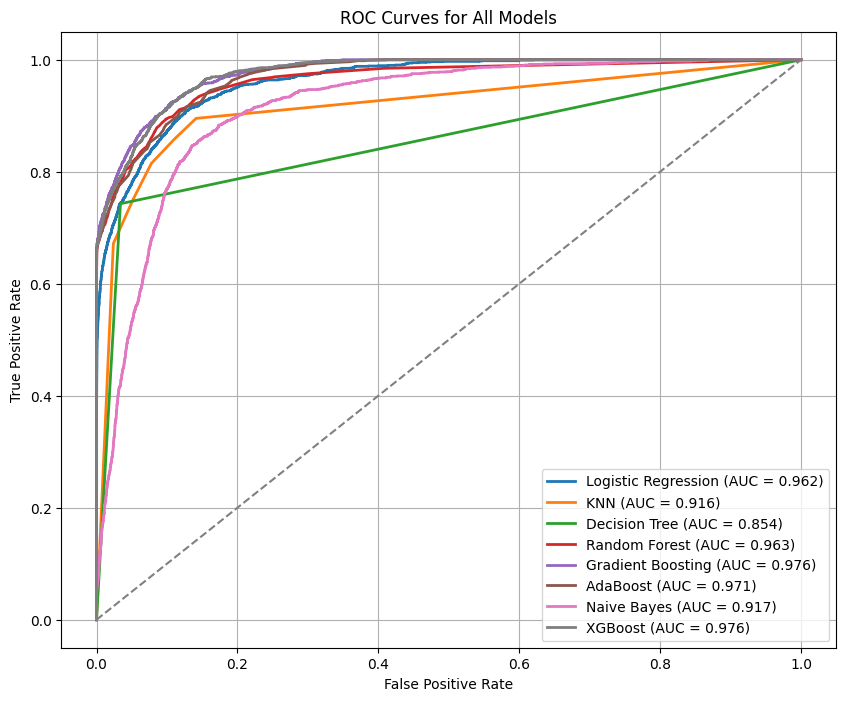

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_prepared)[:, 1]
    else:
        y_scores = model.decision_function(X_test_prepared)
        # Normalize to [0,1]
        y_prob = (y_scores - y_scores.min()) / (y_scores.max() - y_scores.min())

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [ ]:
overfit_models = overfit_df[overfit_df["Train Accuracy"] - overfit_df["Test Accuracy"] > 0.03]["Model"].tolist()

print("🔍 Models considered overfitting and will undergo tuning:")
print(overfit_models)


🔍 Models considered overfitting and will undergo tuning:
['KNN', 'Decision Tree', 'Random Forest']


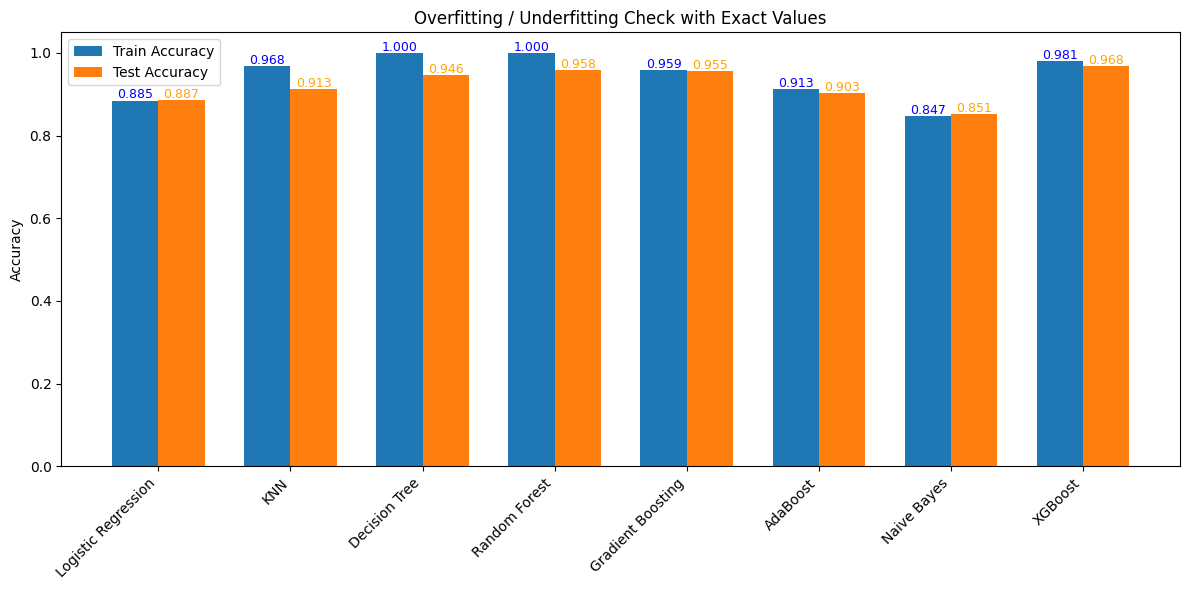

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = overfit_df["Model"]
train_acc = overfit_df["Train Accuracy"]
test_acc = overfit_df["Test Accuracy"]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(12,6))

plt.bar(x - width/2, train_acc, width, label='Train Accuracy')
plt.bar(x + width/2, test_acc, width, label='Test Accuracy')

for i in range(len(models)):
    plt.text(x[i] - width/2, train_acc[i] + 0.005, f"{train_acc[i]:.3f}",
             ha='center', fontsize=9, color='blue')
    plt.text(x[i] + width/2, test_acc[i] + 0.005, f"{test_acc[i]:.3f}",
             ha='center', fontsize=9, color='orange')

plt.xticks(x, models, rotation=45, ha='right')
plt.ylabel("Accuracy")
plt.title("Overfitting / Underfitting Check with Exact Values")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.model_selection import GridSearchCV

best_models = {}

for name in overfit_models:

    if name == "KNN":
        params = {
            "n_neighbors":[3,5,7,9,11],
            "weights":["uniform","distance"],

        }
        model = KNeighborsClassifier()

    elif name == "Decision Tree":
        params = {
            "max_depth":[3,5,10,None],
            "min_samples_split":[2,5,10],

        }
        model = DecisionTreeClassifier()

    elif name == "Random Forest":
        params = {
            "n_estimators":[100,200,300],
            "max_depth":[None,5,10,20],

        }
        model = RandomForestClassifier()

    print(f"\n🚀 Running GridSearch for {name}...")

    grid = GridSearchCV(model, params, scoring="f1", cv=5, n_jobs=-1, verbose=2)
    grid.fit(X_train_balanced, y_train_balanced)

    best_models[name] = grid.best_estimator_
    print("✔ Best Params:", grid.best_params_)



🚀 Running GridSearch for KNN...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
✔ Best Params: {'n_neighbors': 3, 'weights': 'distance'}

🚀 Running GridSearch for Decision Tree...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
✔ Best Params: {'max_depth': None, 'min_samples_split': 5}

🚀 Running GridSearch for Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
✔ Best Params: {'max_depth': None, 'n_estimators': 200}


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Naive Bayes": GaussianNB(),

}



In [ ]:
if xgb_available:
    models["XGBoost"] = XGBClassifier(eval_metric="logloss")


In [ ]:

final_results = []

for name, base_model in models.items():

    model = best_models.get(name, base_model)

    model.fit(X_train_balanced, y_train_balanced)

    y_pred = model.predict(X_test_prepared)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    final_results.append([name, acc, f1])

final_df = pd.DataFrame(final_results, columns=["Model", "Final Accuracy", "Final F1"])
print("\n🏆 FINAL PERFORMANCE AFTER TUNING (FAST - NO GRIDSEARCH RERUN)")
print(final_df.sort_values(by="Final F1", ascending=False))



🏆 FINAL PERFORMANCE AFTER TUNING (FAST - NO GRIDSEARCH RERUN)
                 Model  Final Accuracy  Final F1
7              XGBoost        0.967850  0.793127
4    Gradient Boosting        0.955440  0.758992
3        Random Forest        0.957587  0.757340
2        Decision Tree        0.949471  0.719558
1                  KNN        0.921510  0.637134
5             AdaBoost        0.903498  0.615320
0  Logistic Regression        0.886585  0.581853
6          Naive Bayes        0.851398  0.505575


In [ ]:
overfit_check = []

for name, base_model in models.items():

    model = best_models.get(name, base_model)

    model.fit(X_train_balanced, y_train_balanced)

    train_pred = model.predict(X_train_balanced)
    train_acc = accuracy_score(y_train_balanced, train_pred)

    test_pred = model.predict(X_test_prepared)
    test_acc = accuracy_score(y_test, test_pred)

    gap = train_acc - test_acc  # difference = overfit level

    overfit_check.append([name, train_acc, test_acc, gap])

overfit_df_final = pd.DataFrame(overfit_check, columns=["Model", "Train Accuracy", "Test Accuracy", "Accuracy Gap"])
print("\n📊 OVERFITTING CHECK AFTER TUNING")
print(overfit_df_final.sort_values(by="Accuracy Gap", ascending=False))



📊 OVERFITTING CHECK AFTER TUNING
                 Model  Train Accuracy  Test Accuracy  Accuracy Gap
1                  KNN        0.999533       0.921510      0.078023
2        Decision Tree        0.993825       0.949366      0.044458
3        Random Forest        0.999533       0.958058      0.041475
7              XGBoost        0.980755       0.967850      0.012905
5             AdaBoost        0.912997       0.903498      0.009500
4    Gradient Boosting        0.959156       0.955440      0.003715
0  Logistic Regression        0.884604       0.886585     -0.001981
6          Naive Bayes        0.846718       0.851398     -0.004680


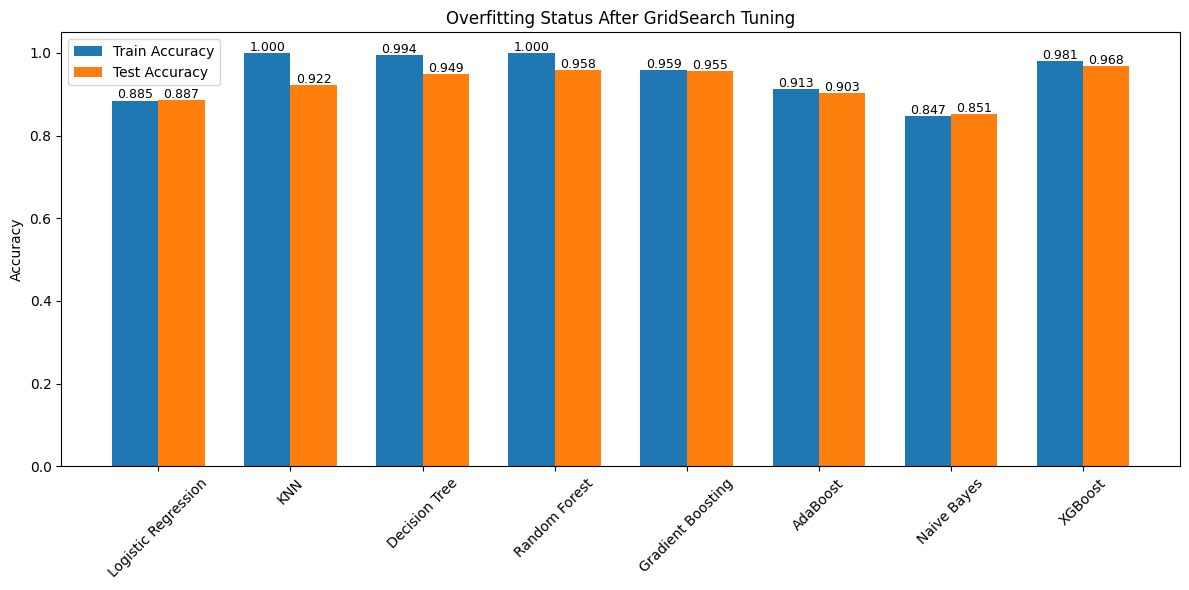

In [ ]:
models_name = overfit_df_final["Model"]
train_acc = overfit_df_final["Train Accuracy"]
test_acc = overfit_df_final["Test Accuracy"]

x = np.arange(len(models_name))
width = 0.35

plt.figure(figsize=(12,6))
plt.bar(x-width/2, train_acc, width, label='Train Accuracy')
plt.bar(x+width/2, test_acc, width, label='Test Accuracy')

for i in range(len(models_name)):
    plt.text(x[i]-width/2, train_acc[i]+0.005, f"{train_acc[i]:.3f}",ha='center',fontsize=9)
    plt.text(x[i]+width/2, test_acc[i]+0.005, f"{test_acc[i]:.3f}",ha='center',fontsize=9)

plt.xticks(x, models_name, rotation=45)
plt.ylabel("Accuracy")
plt.title("Overfitting Status After GridSearch Tuning")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

knn_candidates = [
    {"n_neighbors": 3,  "weights": "distance"},   # current best from GridSearch
    {"n_neighbors": 5,  "weights": "distance"},
    {"n_neighbors": 10, "weights": "uniform"},
    {"n_neighbors": 15, "weights": "uniform"},
    {"n_neighbors": 20, "weights": "uniform"},
]

knn_rows = []

for params in knn_candidates:
    model = KNeighborsClassifier(**params)
    model.fit(X_train_balanced, y_train_balanced)

    y_train_pred = model.predict(X_train_balanced)
    y_test_pred = model.predict(X_test_prepared)

    train_acc = accuracy_score(y_train_balanced, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    gap = train_acc - test_acc
    f1  = f1_score(y_test, y_test_pred)

    knn_rows.append({
        "n_neighbors": params["n_neighbors"],
        "weights": params["weights"],
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Accuracy Gap": gap,
        "Test F1": f1
    })

tune_knn_df = pd.DataFrame(knn_rows)
print("\n🔎 KNN tuning results (sorted by low gap, high test accuracy):")
tune_knn_df = tune_knn_df.sort_values(by=["Accuracy Gap","Test Accuracy"], ascending=[True, False])
print(tune_knn_df)



🔎 KNN tuning results (sorted by low gap, high test accuracy):
   n_neighbors   weights  Train Accuracy  Test Accuracy  Accuracy Gap  \
4           20   uniform        0.940794       0.895958      0.044837   
2           10   uniform        0.956132       0.906901      0.049231   
3           15   uniform        0.944894       0.892502      0.052393   
0            3  distance        0.999533       0.921510      0.078023   
1            5  distance        0.999533       0.915698      0.083835   

    Test F1  
4  0.597203  
2  0.614484  
3  0.588495  
0  0.637134  
1  0.626450  


In [ ]:
best_knn = tune_knn_df.iloc[0]
final_knn = KNeighborsClassifier(
    n_neighbors = int(best_knn["n_neighbors"]),
    weights     = best_knn["weights"]
)


In [ ]:
dt_candidates = [
    {"max_depth": 4,  "min_samples_split": 5},
    {"max_depth": 6,  "min_samples_split": 5},
    {"max_depth": 8,  "min_samples_split": 10},
    {"max_depth": 10, "min_samples_split": 10},
    {"max_depth": None, "min_samples_split": 5},  # previous best
]

dt_rows = []

for params in dt_candidates:
    model = DecisionTreeClassifier(
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        random_state=42
    )
    model.fit(X_train_balanced, y_train_balanced)

    y_train_pred = model.predict(X_train_balanced)
    y_test_pred  = model.predict(X_test_prepared)

    train_acc = accuracy_score(y_train_balanced, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    gap = train_acc - test_acc
    f1  = f1_score(y_test, y_test_pred)

    dt_rows.append({
        "max_depth": params["max_depth"],
        "min_samples_split": params["min_samples_split"],
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Accuracy Gap": gap,
        "Test F1": f1
    })

tune_dt_df = pd.DataFrame(dt_rows)
print("\n🌳 Decision Tree tuning results:")
tune_dt_df = tune_dt_df.sort_values(by=["Accuracy Gap","Test Accuracy"], ascending=[True, False])
print(tune_dt_df)



🌳 Decision Tree tuning results:
   max_depth  min_samples_split  Train Accuracy  Test Accuracy  Accuracy Gap  \
1        6.0                  5        0.901199       0.915855     -0.014656   
3       10.0                 10        0.922892       0.905016      0.017876   
2        8.0                 10        0.914412       0.891926      0.022486   
4        NaN                  5        0.993911       0.949105      0.044806   
0        4.0                  5        0.855443       0.770500      0.084944   

    Test F1  
1  0.641535  
3  0.614862  
2  0.591125  
4  0.716948  
0  0.422758  


In [ ]:
best_dt = tune_dt_df.iloc[0]
final_dt = DecisionTreeClassifier(
    max_depth = None if pd.isna(best_dt["max_depth"]) else int(best_dt["max_depth"]),
    min_samples_split = int(best_dt["min_samples_split"]),
    random_state = 42
)


In [ ]:
rf_candidates = [
    {"n_estimators": 100, "max_depth": 8},
    {"n_estimators": 200, "max_depth": 8},
    {"n_estimators": 200, "max_depth": 10},
    {"n_estimators": 200, "max_depth": None},  # previous best
    {"n_estimators": 300, "max_depth": 10},
]

rf_rows = []

for params in rf_candidates:
    model = RandomForestClassifier(
        n_estimators = params["n_estimators"],
        max_depth    = params["max_depth"],
        random_state = 42
    )
    model.fit(X_train_balanced, y_train_balanced)

    y_train_pred = model.predict(X_train_balanced)
    y_test_pred  = model.predict(X_test_prepared)

    train_acc = accuracy_score(y_train_balanced, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    gap = train_acc - test_acc
    f1  = f1_score(y_test, y_test_pred)

    rf_rows.append({
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Accuracy Gap": gap,
        "Test F1": f1
    })

tune_rf_df = pd.DataFrame(rf_rows)
print("\n🌲 Random Forest tuning results:")
tune_rf_df = tune_rf_df.sort_values(by=["Accuracy Gap","Test Accuracy"], ascending=[True, False])
print(tune_rf_df)



🌲 Random Forest tuning results:
   n_estimators  max_depth  Train Accuracy  Test Accuracy  Accuracy Gap  \
1           200        8.0        0.917155       0.915122      0.002033   
0           100        8.0        0.917737       0.913080      0.004657   
4           300       10.0        0.925111       0.915331      0.009780   
2           200       10.0        0.925241       0.915227      0.010014   
3           200        NaN        0.999533       0.957221      0.042313   

    Test F1  
1  0.647991  
0  0.643471  
4  0.649621  
2  0.648578  
3  0.755462  


In [ ]:
best_rf = tune_rf_df.iloc[0]
final_rf = RandomForestClassifier(
    n_estimators = int(best_rf["n_estimators"]),
    max_depth    = None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
    random_state = 42
)

In [ ]:
final_models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "KNN": final_knn,
    "Decision Tree": final_dt,
    "Random Forest": final_rf,
    "Gradient Boosting": GradientBoostingClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Naive Bayes": GaussianNB()
}
if xgb_available:
    final_models["XGBoost"] = XGBClassifier(eval_metric="logloss")


In [ ]:
final_rows = []

for name, model in final_models.items():
    model.fit(X_train_balanced, y_train_balanced)

    y_train_pred = model.predict(X_train_balanced)
    train_acc = accuracy_score(y_train_balanced, y_train_pred)

    y_test_pred = model.predict(X_test_prepared)
    test_acc = accuracy_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)
    gap = train_acc - test_acc

    final_rows.append([name, train_acc, test_acc, gap, f1])

final_overfit_df = pd.DataFrame(
    final_rows,
    columns=["Model", "Train Accuracy", "Test Accuracy", "Accuracy Gap", "Test F1"]
)

print("\n📊 FINAL OVERFITTING CHECK AFTER MANUAL TUNING")
print(final_overfit_df.sort_values(by="Accuracy Gap", ascending=False))
print("\n🏆 FINAL RANKING BY F1")
print(final_overfit_df.sort_values(by="Test F1", ascending=False))



📊 FINAL OVERFITTING CHECK AFTER MANUAL TUNING
                 Model  Train Accuracy  Test Accuracy  Accuracy Gap   Test F1
1                  KNN        0.940794       0.895958      0.044837  0.597203
7              XGBoost        0.980755       0.967850      0.012905  0.793127
5             AdaBoost        0.912997       0.903498      0.009500  0.615320
4    Gradient Boosting        0.959156       0.955440      0.003715  0.758992
3        Random Forest        0.917155       0.915122      0.002033  0.647991
0  Logistic Regression        0.884604       0.886585     -0.001981  0.581853
6          Naive Bayes        0.846718       0.851398     -0.004680  0.505575
2        Decision Tree        0.901199       0.915855     -0.014656  0.641535

🏆 FINAL RANKING BY F1
                 Model  Train Accuracy  Test Accuracy  Accuracy Gap   Test F1
7              XGBoost        0.980755       0.967850      0.012905  0.793127
4    Gradient Boosting        0.959156       0.955440      0.003715  0.7

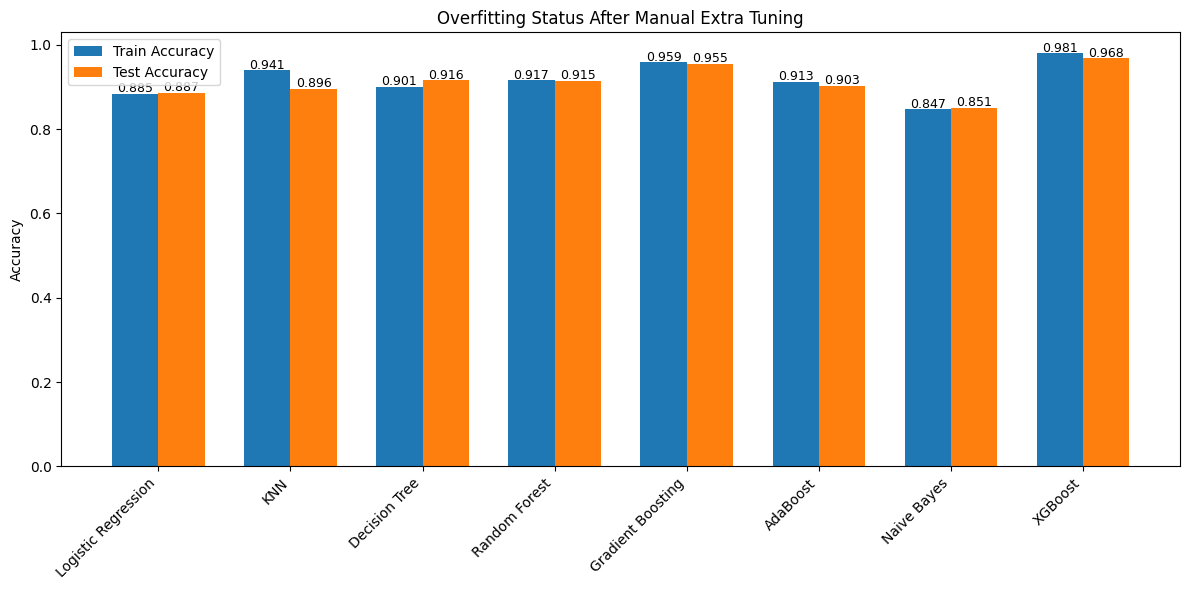

In [ ]:
models_name = final_overfit_df["Model"]
train_acc = final_overfit_df["Train Accuracy"]
test_acc  = final_overfit_df["Test Accuracy"]

x = np.arange(len(models_name))
width = 0.35

plt.figure(figsize=(12,6))
plt.bar(x - width/2, train_acc, width, label="Train Accuracy")
plt.bar(x + width/2, test_acc, width, label="Test Accuracy")

for i in range(len(models_name)):
    plt.text(x[i] - width/2, train_acc[i] + 0.003, f"{train_acc[i]:.3f}", ha="center", fontsize=9)
    plt.text(x[i] + width/2, test_acc[i] + 0.003,  f"{test_acc[i]:.3f}",  ha="center", fontsize=9)

plt.xticks(x, models_name, rotation=45, ha="right")
plt.ylabel("Accuracy")
plt.title("Overfitting Status After Manual Extra Tuning")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
compare = pd.DataFrame({
    "Model": overfit_df["Model"],
    "Before Tuning Test Acc": overfit_df["Test Accuracy"],
    "After GridSearch Test Acc": final_df["Final Accuracy"],
    "After Manual Tuning Test Acc": final_overfit_df["Test Accuracy"]
})

print("\n📊 Full Comparison (Before → GridSearch → Manual)")
print(compare.sort_values(by="After Manual Tuning Test Acc", ascending=False))



📊 Full Comparison (Before → GridSearch → Manual)
                 Model  Before Tuning Test Acc  After GridSearch Test Acc  \
7              XGBoost                0.967850                   0.967850   
4    Gradient Boosting                0.955440                   0.955440   
2        Decision Tree                0.946225                   0.949471   
3        Random Forest                0.957535                   0.957587   
5             AdaBoost                0.903498                   0.903498   
1                  KNN                0.912661                   0.921510   
0  Logistic Regression                0.886585                   0.886585   
6          Naive Bayes                0.851398                   0.851398   

   After Manual Tuning Test Acc  
7                      0.967850  
4                      0.955440  
2                      0.915855  
3                      0.915122  
5                      0.903498  
1                      0.895958  
0                 

In [ ]:
import pandas as pd

compare = pd.DataFrame({
    "Model": ["Logistic Regression","KNN","Decision Tree","Random Forest","Gradient Boosting","AdaBoost","Naive Bayes","XGBoost"],
    "Before": [0.887,0.913,0.946,0.957,0.955,0.903,0.851,0.968],
    "Grid":   [0.887,0.922,0.949,0.957,0.955,0.903,0.851,0.968],
    "Manual": [0.887,0.896,0.916,0.915,0.955,0.903,0.851,0.968]
}).set_index("Model")


/tmp/ipython-input-481535183.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(x[i]-w, compare["Before"][i]+0.002, f"{compare['Before'][i]:.3f}", ha='center')
/tmp/ipython-input-481535183.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(x[i],   compare["Grid"][i]+0.002,   f"{compare['Grid'][i]:.3f}",   ha='center')
/tmp/ipython-input-481535183.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(x[i

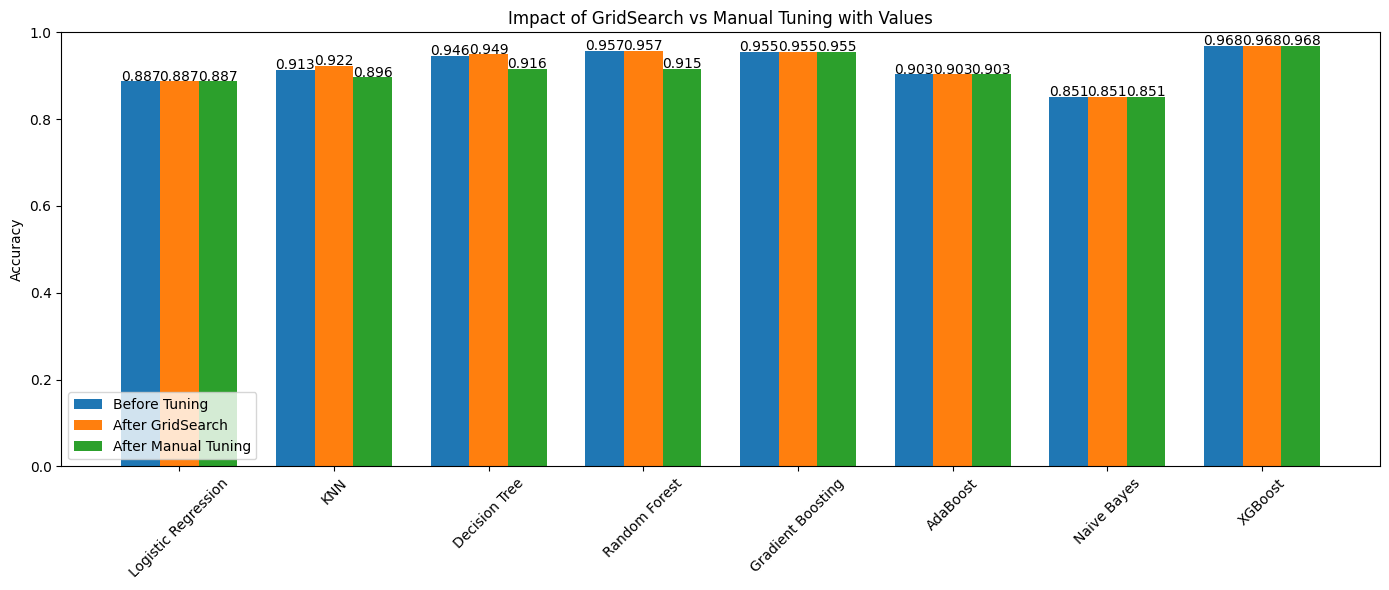

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(compare.index))
w = 0.25

plt.figure(figsize=(14,6))
plt.bar(x-w, compare["Before"], width=w, label="Before Tuning")
plt.bar(x,   compare["Grid"],   width=w, label="After GridSearch")
plt.bar(x+w, compare["Manual"], width=w, label="After Manual Tuning")

for i, model in enumerate(compare.index):
    plt.text(x[i]-w, compare["Before"][i]+0.002, f"{compare['Before'][i]:.3f}", ha='center')
    plt.text(x[i],   compare["Grid"][i]+0.002,   f"{compare['Grid'][i]:.3f}",   ha='center')
    plt.text(x[i]+w, compare["Manual"][i]+0.002, f"{compare['Manual'][i]:.3f}", ha='center')

plt.xticks(x, compare.index, rotation=45)
plt.ylim(0.00,1.00)
plt.ylabel("Accuracy")
plt.title("Impact of GridSearch vs Manual Tuning with Values")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
final_trained_models = {}

for name, base_model in models.items():
    model = best_models.get(name, base_model)
    model.fit(X_train_balanced, y_train_balanced)
    final_trained_models[name] = model


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

final_comparison = []

for name, model in final_trained_models.items():
    y_pred = model.predict(X_test_prepared)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)

    final_comparison.append([name, acc, f1])

final_comparison_df = pd.DataFrame(
    final_comparison,
    columns=["Model", "Test Accuracy", "Test F1"]
).sort_values(by="Test F1", ascending=False)

print("🏆 FINAL MODEL COMPARISON (AFTER TUNING)")
print(final_comparison_df)


🏆 FINAL MODEL COMPARISON (AFTER TUNING)
                 Model  Test Accuracy   Test F1
7              XGBoost       0.967850  0.793127
4    Gradient Boosting       0.955440  0.758992
3        Random Forest       0.957587  0.757775
2        Decision Tree       0.948581  0.715527
1                  KNN       0.921510  0.637134
5             AdaBoost       0.903498  0.615320
0  Logistic Regression       0.886585  0.581853
6          Naive Bayes       0.851398  0.505575


In [ ]:
import joblib

joblib.dump(final_models["XGBoost"], "final_diabetes_model.pkl")
print("Model saved as final_diabetes_model.pkl")


Model saved as final_diabetes_model.pkl


In [ ]:
model = joblib.load("final_diabetes_model.pkl")
prediction = model.predict(X_test_prepared)


<Figure size 600x500 with 0 Axes>

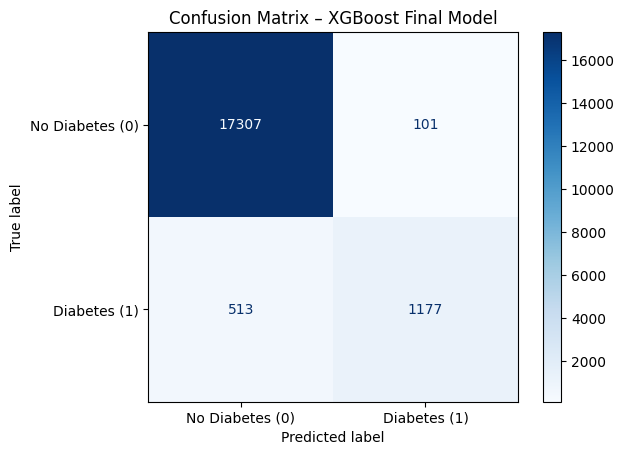

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test_prepared)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes (0)", "Diabetes (1)"])
plt.figure(figsize=(6,5))
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – XGBoost Final Model")
plt.show()


<Figure size 500x400 with 0 Axes>

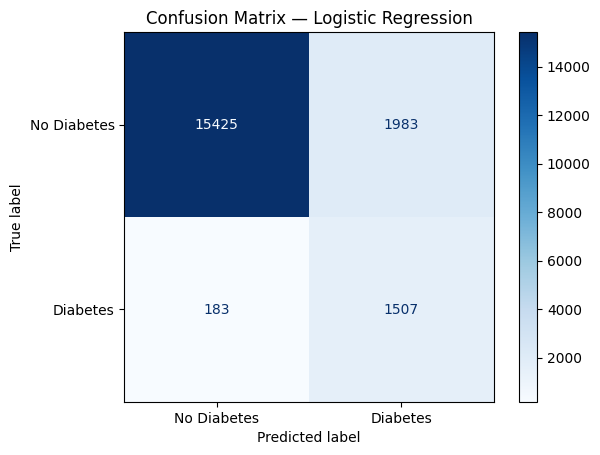

<Figure size 500x400 with 0 Axes>

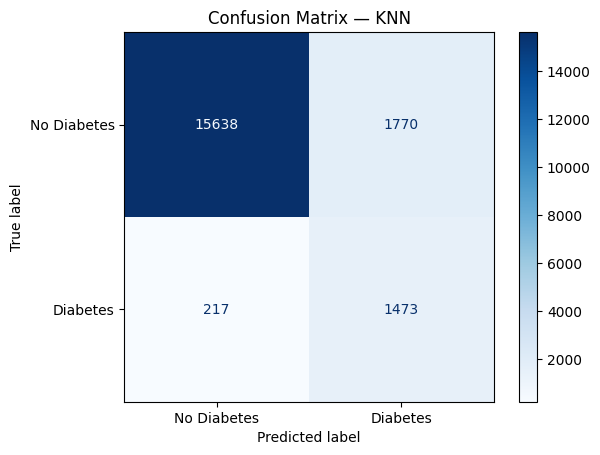

<Figure size 500x400 with 0 Axes>

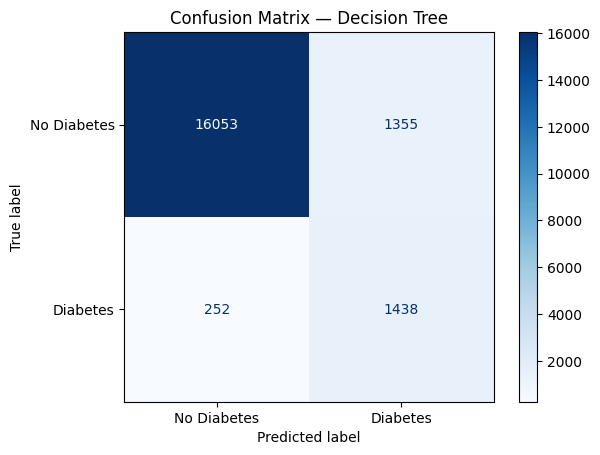

<Figure size 500x400 with 0 Axes>

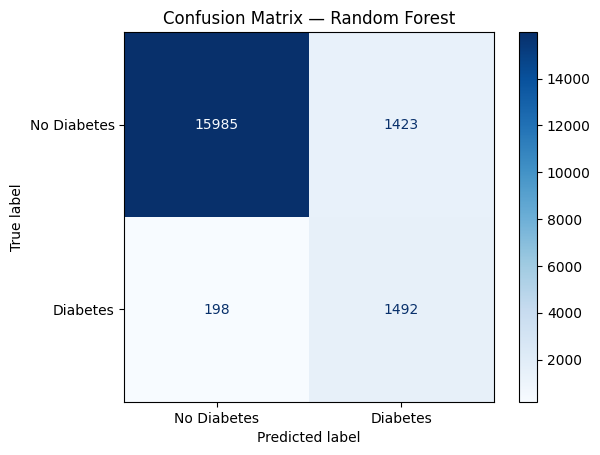

<Figure size 500x400 with 0 Axes>

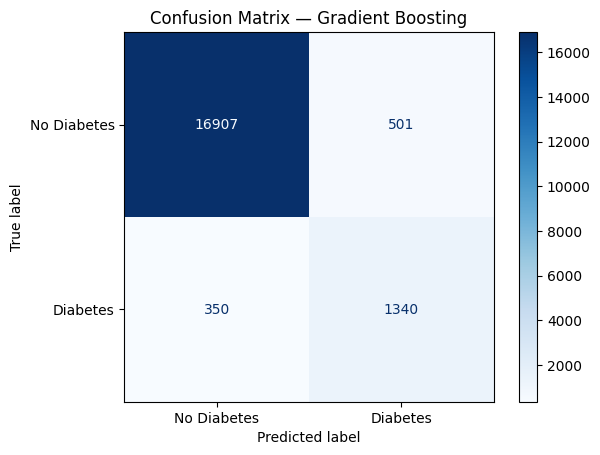

<Figure size 500x400 with 0 Axes>

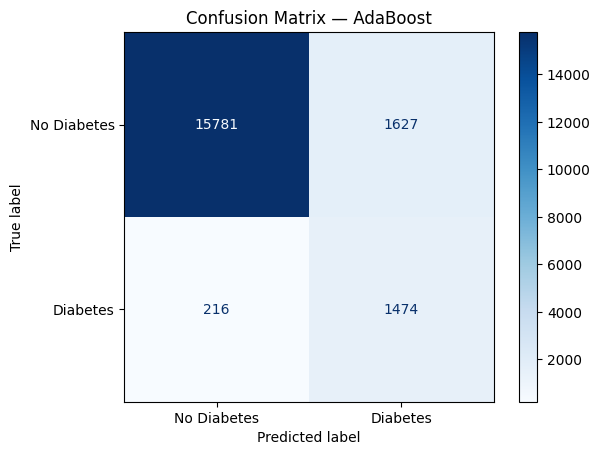

<Figure size 500x400 with 0 Axes>

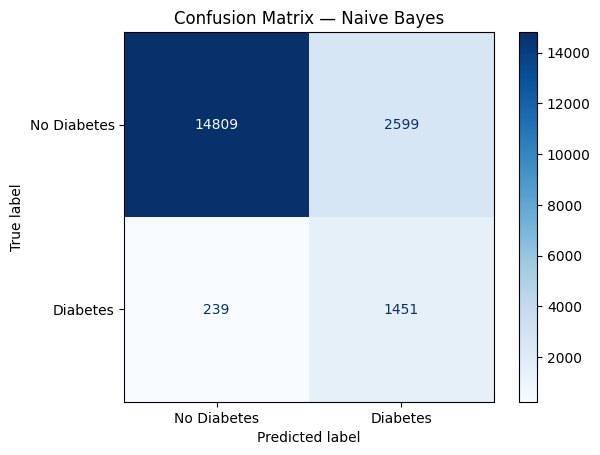

<Figure size 500x400 with 0 Axes>

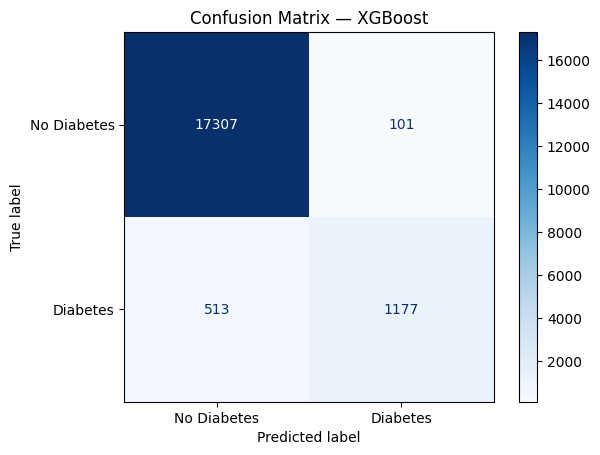

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in final_models.items():

    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_prepared)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["No Diabetes","Diabetes"])

    plt.figure(figsize=(5,4))
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.show()


In [ ]:
joblib.dump(preprocessor, "preprocessor.pkl")
print("Preprocessor saved successfully!")


Preprocessor saved successfully!


In [ ]:
joblib.dump(final_models["XGBoost"], "final_diabetes_model.pkl")


['final_diabetes_model.pkl']

In [ ]:
print(df.columns)


Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'sugar_lvl'],
      dtype='object')
